# Inteligencia Artificial — Tarea 4
**Puntos 1, 2, 3 y 4:** convolución a mano, datos y MLP, CNN y arquitectura, y análisis.
**Integrantes:** Laura Ruidiaz y Angelo Maiale

Estructura del proyecto:
- `convolucion.py`: convolución, ReLU y max pooling implementados a mano; fórmulas de parámetros (punto 1).
- `datos.py`: semilla, carga de FashionMNIST, separación train/val/test y gráficas (punto 2).
- `modelos.py`: clases `MLP(nn.Module)` y `CNN(nn.Module)`, y tabla/verificación de capas (`resumen_capas`) (puntos 2 y 3).
- `entrenamiento.py`: ciclo de entrenamiento (con `weight_decay` y early stopping), evaluación, curvas, matriz de confusión, imágenes mal clasificadas y visualización de filtros (puntos 2, 3 y 4).

In [1]:
import inspect
import torch
import torch.nn as nn

from datos import (SEMILLA, NOMBRES_CLASES, fijar_semilla, obtener_dispositivo, cargar_datasets,
                   crear_dataloaders, mostrar_ejemplos, proporcion_por_clase, obtener_etiquetas)
from convolucion import (convolucion_manual, relu_manual, maxpool_manual, explicar_convolucion,
                         explicar_maxpool, parametros_conv, parametros_densa)
from modelos import MLP, CNN, resumen_capas
from entrenamiento import (entrenar, evaluar, graficar_curvas, comparar_curvas_regularizacion,
                           contar_parametros, predecir_conjunto, graficar_matriz_confusion,
                           mostrar_mal_clasificadas, visualizar_filtros_conv1)

fijar_semilla(SEMILLA)
dispositivo = obtener_dispositivo()
print("Semilla:", SEMILLA, "| Dispositivo:", dispositivo)

Semilla: 42 | Dispositivo: cpu


---
## Punto 1. Convolución a mano

Considere la imagen $X$ de $5\times 5$ y el filtro $K$ de $3\times 3$ del enunciado:

$$
X=\begin{pmatrix}1&0&2&1&0\\0&1&3&1&1\\2&1&0&0&2\\1&0&1&2&1\\0&2&1&1&0\end{pmatrix},\qquad
K=\begin{pmatrix}1&0&-1\\1&0&-1\\1&0&-1\end{pmatrix}
$$

Con stride $s=1$ y sin padding ($p=0$), el tamaño de salida es $(5-3)/1+1 = 3$ en cada dimensión, es decir, **3 × 3**.
Cada elemento $(i,j)$ de la salida es la suma de los productos elemento a elemento entre el filtro $K$ y la ventana $3\times 3$ de la imagen $X[i:i+3,\; j:j+3]$
(`nn.Conv2d` en PyTorch calcula correlación cruzada: no voltea el filtro).

Como $K$ tiene $1$ en la columna izquierda, $0$ en la columna central y $-1$ en la columna derecha, cada salida es
*(suma de la columna izquierda de la ventana) − (suma de la columna derecha de la ventana)*: un **detector de bordes verticales**.

In [2]:
X = torch.tensor([[1, 0, 2, 1, 0],
                  [0, 1, 3, 1, 1],
                  [2, 1, 0, 0, 2],
                  [1, 0, 1, 2, 1],
                  [0, 2, 1, 1, 0]], dtype=torch.float32)
K = torch.tensor([[1, 0, -1],
                  [1, 0, -1],
                  [1, 0, -1]], dtype=torch.float32)

print("Cálculo paso a paso de la convolución (stride 1, sin padding, sin sesgo):")
explicar_convolucion(X, K, stride=1)

Cálculo paso a paso de la convolución (stride 1, sin padding, sin sesgo):
salida[0,0] = 1 + 0 + -2 + 0 + 0 + -3 + 2 + 0 + 0 = -2
salida[0,1] = 0 + 0 + -1 + 1 + 0 + -1 + 1 + 0 + 0 = 0
salida[0,2] = 2 + 0 + 0 + 3 + 0 + -1 + 0 + 0 + -2 = 2
salida[1,0] = 0 + 0 + -3 + 2 + 0 + 0 + 1 + 0 + -1 = -1
salida[1,1] = 1 + 0 + -1 + 1 + 0 + 0 + 0 + 0 + -2 = -1
salida[1,2] = 3 + 0 + -1 + 0 + 0 + -2 + 1 + 0 + -1 = 0
salida[2,0] = 2 + 0 + 0 + 1 + 0 + -1 + 0 + 0 + -1 = 1
salida[2,1] = 1 + 0 + 0 + 0 + 0 + -2 + 2 + 0 + -1 = 0
salida[2,2] = 0 + 0 + -2 + 1 + 0 + -1 + 1 + 0 + 0 = -1


### Resultado de la convolución (a mano)

| | col 0 | col 1 | col 2 |
|---|---|---|---|
| **fila 0** | $(1+0+2)-(2+3+0)=3-5=-2$ | $(0+1+1)-(1+1+0)=2-2=0$ | $(2+3+0)-(0+1+2)=5-3=2$ |
| **fila 1** | $(0+2+1)-(3+0+1)=3-4=-1$ | $(1+1+0)-(1+0+2)=2-3=-1$ | $(3+0+1)-(1+2+1)=4-4=0$ |
| **fila 2** | $(2+1+0)-(0+1+1)=3-2=1$ | $(1+0+2)-(0+2+1)=3-3=0$ | $(0+1+1)-(2+1+0)=2-3=-1$ |

$$
\text{Conv}(X,K)=\begin{pmatrix}-2&0&2\\-1&-1&0\\1&0&-1\end{pmatrix}
$$

### ReLU

Se aplica $\operatorname{ReLU}(z)=\max(0,z)$, reemplazando los valores negativos por $0$:

$$
\text{ReLU}(\text{Conv}(X,K))=\begin{pmatrix}0&0&2\\0&0&0\\1&0&0\end{pmatrix}
$$

### Max pooling 2 × 2, stride 1

La entrada mide $3\times 3$, por lo que con ventana $2\times 2$ y stride $1$ la salida mide $(3-2)/1+1=2$ por lado: **2 × 2**.

$$
\text{MaxPool}=\begin{pmatrix}\max(0,0,0,0)&\max(0,2,0,0)\\\max(0,0,1,0)&\max(0,0,0,0)\end{pmatrix}=\begin{pmatrix}0&2\\1&0\end{pmatrix}
$$

In [3]:
# Mismo cálculo con las funciones hechas a mano
conv_manual = convolucion_manual(X, K, stride=1, padding=0)
relu_resultado = relu_manual(conv_manual)
print("Convolución:\n", conv_manual)
print("\nReLU:\n", relu_resultado)
print("\nMax pooling 2x2, stride 1 (paso a paso):")
explicar_maxpool(relu_resultado, tam=2, stride=1)
pool_manual = maxpool_manual(relu_resultado, tam=2, stride=1)
print("\nResultado:\n", pool_manual)

# Resultados obtenidos a mano en las celdas de arriba
esperado_conv = torch.tensor([[-2., 0., 2.], [-1., -1., 0.], [1., 0., -1.]])
esperado_pool = torch.tensor([[0., 2.], [1., 0.]])
assert torch.equal(conv_manual, esperado_conv)
assert torch.equal(pool_manual, esperado_pool)
print("\nLas funciones manuales coinciden exactamente con el cálculo hecho a mano.")

Convolución:
 tensor([[-2.,  0.,  2.],
        [-1., -1.,  0.],
        [ 1.,  0., -1.]])

ReLU:
 tensor([[0., 0., 2.],
        [0., 0., 0.],
        [1., 0., 0.]])

Max pooling 2x2, stride 1 (paso a paso):
salida[0,0] = max(0, 0, 0, 0) = 0
salida[0,1] = max(0, 2, 0, 0) = 2
salida[1,0] = max(0, 0, 1, 0) = 1
salida[1,1] = max(0, 0, 0, 0) = 0

Resultado:
 tensor([[0., 2.],
        [1., 0.]])

Las funciones manuales coinciden exactamente con el cálculo hecho a mano.


### Verificación con `nn.Conv2d` y `nn.MaxPool2d` (pesos asignados a mano)

In [4]:
conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, stride=1, padding=0, bias=False)
with torch.no_grad():
    conv.weight.copy_(K.view(1, 1, 3, 3))   # forma (c_out, c_in, kh, kw)

pool = nn.MaxPool2d(kernel_size=2, stride=1)
relu = nn.ReLU()

with torch.no_grad():
    x_img = X.view(1, 1, 5, 5)              # (batch, canales, alto, ancho)
    salida_conv = conv(x_img)
    salida_pool = pool(relu(salida_conv))

print("nn.Conv2d:\n", salida_conv.squeeze())
print("\nnn.MaxPool2d tras ReLU:\n", salida_pool.squeeze())

assert torch.allclose(salida_conv.squeeze(), esperado_conv)
assert torch.allclose(salida_pool.squeeze(), esperado_pool)
print("\n¿Conv coincide con el cálculo a mano? ", torch.allclose(salida_conv.squeeze(), esperado_conv))
print("¿Pool coincide con el cálculo a mano? ", torch.allclose(salida_pool.squeeze(), esperado_pool))

nn.Conv2d:
 tensor([[-2.,  0.,  2.],
        [-1., -1.,  0.],
        [ 1.,  0., -1.]])

nn.MaxPool2d tras ReLU:
 tensor([[0., 2.],
        [1., 0.]])

¿Conv coincide con el cálculo a mano?  True
¿Pool coincide con el cálculo a mano?  True


### Parámetros: capa convolucional vs. capa densa

**`nn.Conv2d(3, 16, kernel_size=3)`**: cada uno de los $16$ filtros tiene dimensión $3\times 3\times 3 = 27$ pesos más $1$ sesgo (`bias=True` por defecto en PyTorch):
$$16\cdot(3\cdot 3\cdot 3) + 16 = 432 + 16 = \mathbf{448\text{ parámetros}} \quad (\text{o } 432 \text{ sin sesgo})$$

**Capa densa** que recibe una imagen de $32\times 32\times 3$ ($3\,072$ entradas) y produce una salida de $30\times 30\times 16$ ($14\,400$ neuronas): cada neurona de salida se conecta con todas las entradas:
$$3\,072\cdot 14\,400 + 14\,400 = 44\,236\,800 + 14\,400 = \mathbf{44\,251\,200\text{ parámetros}} \quad (\text{o } 44\,236\,800 \text{ sin sesgo})$$

La convolución usa **conexiones locales** (cada neurona ve solo una vecindad $3\times 3$) y **pesos compartidos** (el mismo filtro se desplaza sobre toda la imagen), por lo que requiere $\approx 98\,775$ veces menos parámetros.

In [5]:
conv_capa = nn.Conv2d(3, 16, kernel_size=3)
densa = nn.Linear(32 * 32 * 3, 30 * 30 * 16)

p_conv = sum(p.numel() for p in conv_capa.parameters())
p_densa = sum(p.numel() for p in densa.parameters())

print("Conv2d(3, 16, 3):")
for nombre, p in conv_capa.named_parameters():
    print(f"  {nombre}: {tuple(p.shape)} -> {p.numel()}")
print(f"  total (p.numel()): {p_conv} | fórmula: {parametros_conv(3, 16, 3)}")

print("\nCapa densa 3072 -> 14400:")
for nombre, p in densa.named_parameters():
    print(f"  {nombre}: {tuple(p.shape)} -> {p.numel():,}")
print(f"  total (p.numel()): {p_densa:,} | fórmula: {parametros_densa(3072, 14400):,}")

print(f"\nLa capa densa tiene {p_densa / p_conv:,.0f} veces más parámetros.")
del densa

Conv2d(3, 16, 3):
  weight: (16, 3, 3, 3) -> 432
  bias: (16,) -> 16
  total (p.numel()): 448 | fórmula: 448

Capa densa 3072 -> 14400:
  weight: (14400, 3072) -> 44,236,800
  bias: (14400,) -> 14,400
  total (p.numel()): 44,251,200 | fórmula: 44,251,200

La capa densa tiene 98,775 veces más parámetros.


---
## Punto 2. Datos y MLP

**Dataset:** FashionMNIST (`torchvision.datasets`): 10 clases de prendas de vestir, imágenes de $28\times 28$ en escala de grises.
Como el conjunto original de entrenamiento tiene $60\,000$ imágenes (más de $20\,000$), se toma una **muestra aleatoria de 20 000 imágenes** con semilla fija (`SEMILLA = 42`).
Esa muestra se divide en **80 % entrenamiento (16 000)** y **20 % validación (4 000)**. Como conjunto de **prueba** se utiliza el test oficial ($10\,000$ imágenes).
Los índices de la partición se guardan en `splits.pt` para garantizar que todos los modelos de la tarea usen exactamente la misma separación.

In [6]:
train_ds, val_ds, test_ds = cargar_datasets(root="data", n_entrenamiento=20000, frac_val=0.2)
print(f"Entrenamiento: {len(train_ds)} | Validación: {len(val_ds)} | Prueba: {len(test_ds)}")
print("Clases:", NOMBRES_CLASES)

Entrenamiento: 16000 | Validación: 4000 | Prueba: 10000
Clases: ['Camiseta', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo', 'Sandalia', 'Camisa', 'Zapatilla', 'Bolso', 'Botín']


### Imágenes de cada clase

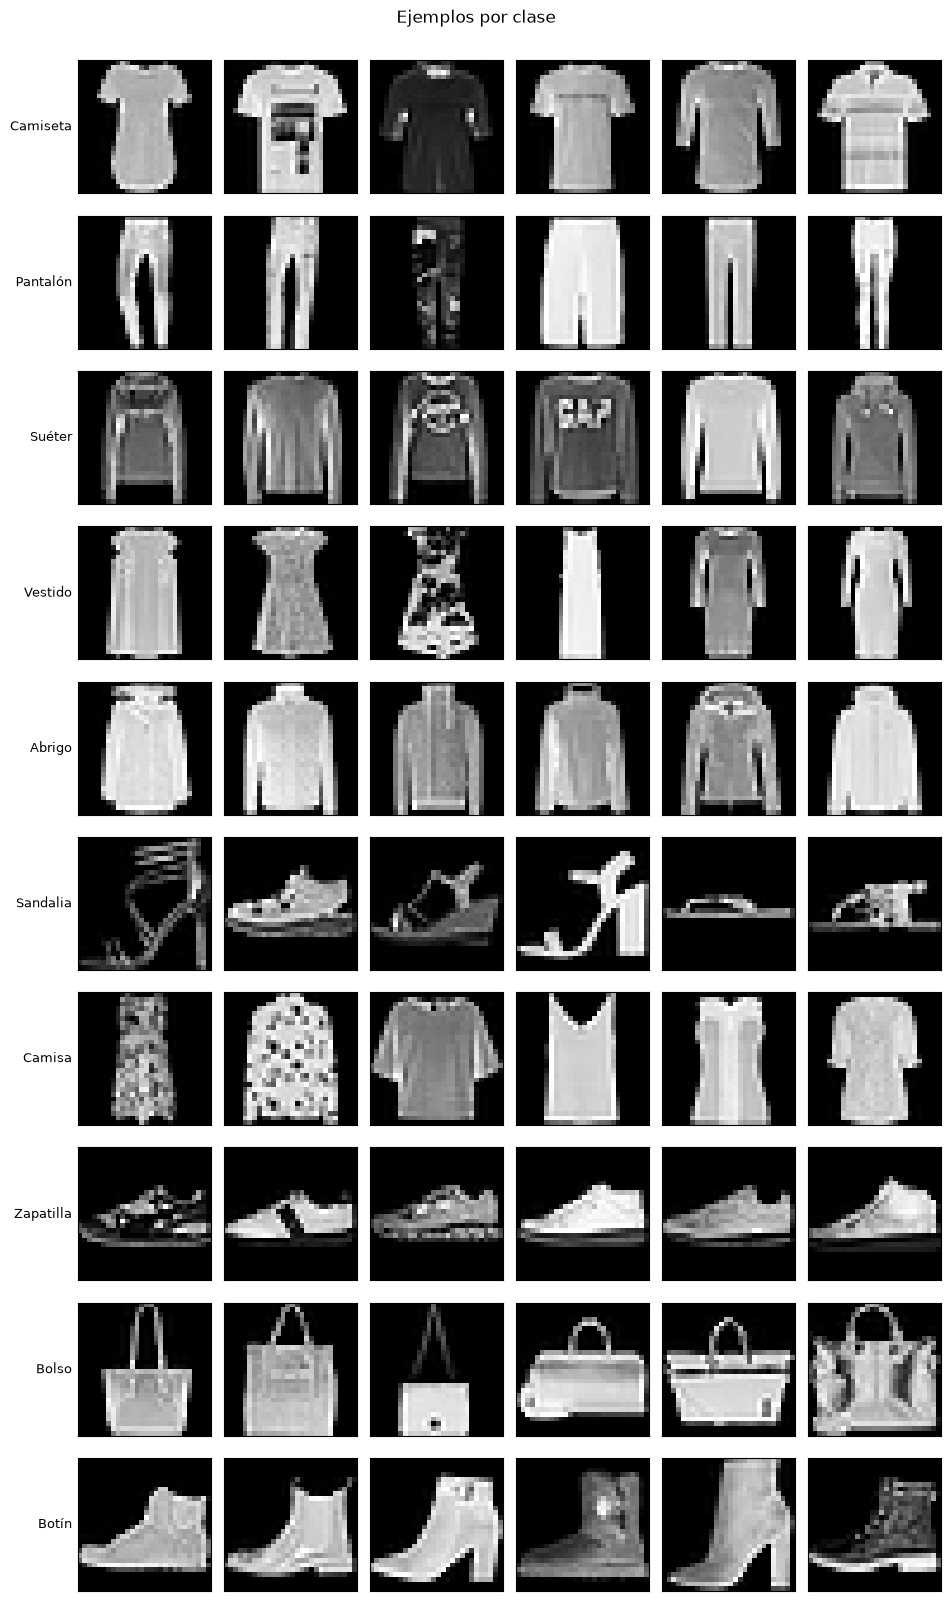

In [7]:
mostrar_ejemplos(train_ds, n_por_clase=6)

### Proporción de ejemplos por clase

Clase          Entrenamiento      Validación          Prueba
Camiseta               9.79%           9.93%          10.00%
Pantalón               9.98%          10.15%          10.00%
Suéter                10.04%          10.82%          10.00%
Vestido                9.97%           9.57%          10.00%
Abrigo                10.21%          10.05%          10.00%
Sandalia              10.19%          10.00%          10.00%
Camisa                10.02%          10.30%          10.00%
Zapatilla             10.31%           9.43%          10.00%
Bolso                  9.62%           9.82%          10.00%
Botín                  9.86%           9.93%          10.00%


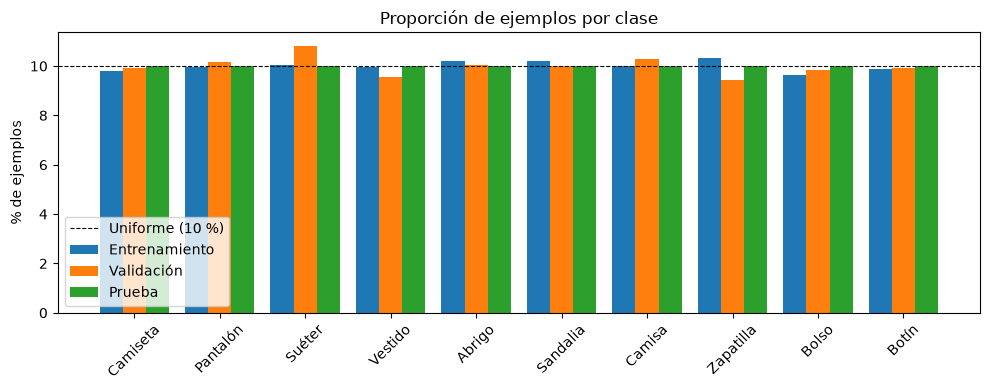

In [8]:
proporcion_por_clase(train_ds, val_ds, test_ds)

Las 10 clases están prácticamente balanceadas (~10 % cada una en entrenamiento, validación y prueba), por lo que la exactitud (*accuracy*) es una métrica adecuada y un clasificador al azar obtendría ~10 %.

In [9]:
# Mismos dataloaders para todos los modelos de la tarea
BATCH_SIZE = 128
train_loader, val_loader, test_loader = crear_dataloaders(train_ds, val_ds, test_ds, batch_size=BATCH_SIZE)

x_batch, y_batch = next(iter(train_loader))
print("Forma de un mini-batch:", tuple(x_batch.shape), tuple(y_batch.shape))
print("Mini-batches por época (pasos por época):", len(train_loader))

Forma de un mini-batch: (128, 1, 28, 28) (128,)
Mini-batches por época (pasos por época): 125


### Modelo: `MLP(nn.Module)`

In [10]:
print(inspect.getsource(MLP))

class MLP(nn.Module):
    """Red totalmente conectada para imágenes 28x28 (escala de grises).

    Entrada (B,1,28,28) -> Flatten -> 784 -> 256 -> 128 -> 10 (logits).
    No se aplica softmax a la salida: nn.CrossEntropyLoss ya lo incluye.
    """

    def __init__(self, in_features=28 * 28, ocultas=(256, 128), n_clases=10):
        super().__init__()
        capas = [nn.Flatten()]
        previo = in_features
        for h in ocultas:
            capas += [nn.Linear(previo, h), nn.ReLU()]
            previo = h
        capas.append(nn.Linear(previo, n_clases))
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)



In [11]:
fijar_semilla(SEMILLA)
mlp = MLP()
print(mlp)
print("\nForma de la salida:", tuple(mlp(x_batch).shape))
print("Parámetros totales del MLP:", f"{contar_parametros(mlp):,}")
for nombre, p in mlp.named_parameters():
    print(f"  {nombre:<14}{str(tuple(p.shape)):<14}{p.numel():>9,}")

MLP(
  (red): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

Forma de la salida: (128, 10)
Parámetros totales del MLP: 235,146
  red.1.weight  (256, 784)      200,704
  red.1.bias    (256,)              256
  red.3.weight  (128, 256)       32,768
  red.3.bias    (128,)              128
  red.5.weight  (10, 128)         1,280
  red.5.bias    (10,)                10


### Entrenamiento del MLP

- **Época:** una pasada completa sobre los $16\,000$ ejemplos de entrenamiento.
- **Mini-batch:** subconjunto de `batch_size = 128` imágenes procesadas juntas.
- **Paso (step):** una actualización de pesos con `optimizador.step()` (1 mini-batch = 1 paso). Con $16\,000 / 128 = 125$ pasos por época y $20$ épocas, el entrenamiento realiza **$125 \times 20 = 2\,500$ pasos**.
- No se aplica `softmax` al final de la red porque `nn.CrossEntropyLoss` combina internamente `LogSoftmax` y `NLLLoss` sobre los *logits* para mayor estabilidad numérica.
- `optimizador.zero_grad()` limpia los gradientes del paso previo; si se omite, PyTorch **acumula (suma)** los gradientes nuevos con los de pasos anteriores.

In [12]:
EPOCAS = 20
LR = 1e-3
print(f"Pasos totales: {len(train_loader)} por época x {EPOCAS} épocas = {len(train_loader) * EPOCAS}\n")

fijar_semilla(SEMILLA)
mlp = MLP()
hist_mlp = entrenar(mlp, train_loader, val_loader, epocas=EPOCAS, lr=LR, dispositivo=dispositivo)

Pasos totales: 125 por época x 20 épocas = 2500



Época  1/20 | pérdida train 0.6726 val 0.4747 | exactitud train 0.7591 val 0.8313


Época  2/20 | pérdida train 0.4312 val 0.4703 | exactitud train 0.8439 val 0.8193


Época  3/20 | pérdida train 0.3776 val 0.4276 | exactitud train 0.8596 val 0.8438


Época  4/20 | pérdida train 0.3439 val 0.4309 | exactitud train 0.8742 val 0.8468


Época  5/20 | pérdida train 0.3083 val 0.3924 | exactitud train 0.8841 val 0.8605


... (11 outputs left out)

Época 17/20 | pérdida train 0.1528 val 0.4372 | exactitud train 0.9422 val 0.8628


Época 18/20 | pérdida train 0.1375 val 0.4581 | exactitud train 0.9477 val 0.8730


Época 19/20 | pérdida train 0.1312 val 0.4653 | exactitud train 0.9496 val 0.8712


Época 20/20 | pérdida train 0.1124 val 0.4970 | exactitud train 0.9584 val 0.8705


### Curvas de pérdida y exactitud del MLP

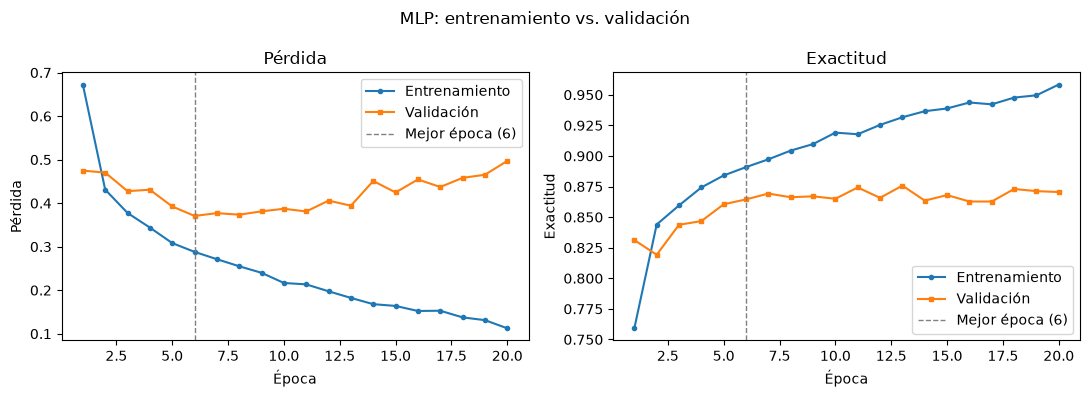

In [13]:
graficar_curvas(hist_mlp, titulo="MLP: entrenamiento vs. validación", marcar_mejor=True)

In [14]:
mejor_ep_mlp = max(range(EPOCAS), key=lambda i: hist_mlp["val_acc"][i])
min_loss_ep_mlp = min(range(EPOCAS), key=lambda i: hist_mlp["val_loss"][i])
print(f"Última época (20) -> train_acc: {hist_mlp['train_acc'][-1]:.4f} | val_acc: {hist_mlp['val_acc'][-1]:.4f} | brecha: {hist_mlp['train_acc'][-1] - hist_mlp['val_acc'][-1]:.4f}")
print(f"Menor val_loss    -> época {min_loss_ep_mlp + 1}: {hist_mlp['val_loss'][min_loss_ep_mlp]:.4f} (val_acc: {hist_mlp['val_acc'][min_loss_ep_mlp]:.4f})")
print(f"Mejor val_acc     -> época {mejor_ep_mlp + 1}: {hist_mlp['val_acc'][mejor_ep_mlp]:.4f}")

Última época (20) -> train_acc: 0.9584 | val_acc: 0.8705 | brecha: 0.0879
Menor val_loss    -> época 6: 0.3707 (val_acc: 0.8645)
Mejor val_acc     -> época 13: 0.8758


**Observaciones sobre el entrenamiento del MLP:**
- **Evolución de la pérdida:** la pérdida de entrenamiento desciende continuamente desde `0.6726` (época 1) hasta `0.1124` (época 20). En cambio, la pérdida de validación alcanza su mínimo en la época 6 (`0.3707`) y a partir de ahí sube hasta `0.4970` en la época 20, síntoma claro de **sobreajuste (*overfitting*)**.
- **Brecha de exactitud:** al final de las 20 épocas, la exactitud de entrenamiento llega a `95.84 %` mientras que la de validación queda en `87.05 %` (con un máximo de `87.58 %` en la época 13), produciendo una brecha de **8.79 puntos porcentuales**.
- **Guardado de pesos:** guardamos el modelo en `mlp.pt`. La exactitud sobre el conjunto de **prueba** se reporta una sola vez al final del Punto 3, tal como exige el enunciado.

In [15]:
torch.save(mlp.state_dict(), "mlp.pt")
print("Pesos del MLP guardados en mlp.pt")

Pesos del MLP guardados en mlp.pt


---
## Punto 3. CNN y arquitectura

### 3.1 Implementación de `class CNN(nn.Module)`

Implementamos la clase `CNN(nn.Module)` en `modelos.py` con al menos 2 bloques compuestos por:
1. `nn.Conv2d(c_in, c_out, kernel_size=k, stride=1, padding=k//2)` (mantiene el alto y ancho del mapa).
2. `nn.ReLU()`.
3. `nn.MaxPool2d(kernel_size=2, stride=2)` (reduce el alto y ancho a la mitad).

Tras los bloques convolucionales se aplica `nn.Flatten()` y capas densas (`nn.Linear` + `nn.ReLU`, con `nn.Dropout` opcional para regularización) hasta la capa de salida de $10$ clases (logits).

In [16]:
print(inspect.getsource(CNN))

class CNN(nn.Module):
    """Red convolucional para imágenes 1x28x28 (FashionMNIST).

    Consta de al menos 2 bloques [Conv2d -> ReLU -> MaxPool2d(2, 2)],
    seguidos de Flatten y capas densas (con ReLU y Dropout opcional).
    No se aplica softmax al final porque nn.CrossEntropyLoss recibe logits.
    """

    def __init__(self, in_channels=1, lado_imagen=28, canales=(16, 32),
                 kernel_size=3, ocultas=(128,), dropout=0.0, n_clases=10):
        super().__init__()
        padding = kernel_size // 2  # mantiene alto y ancho en la convolución
        capas = []
        c_prev = in_channels
        lado = lado_imagen
        for c_out in canales:
            capas += [
                nn.Conv2d(c_prev, c_out, kernel_size=kernel_size, stride=1, padding=padding),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
            ]
            c_prev = c_out
            lado = lado // 2  # cada MaxPool2d(2, 2) divide el tamaño espacial entre 2

    

### 3.2 Tabla de formas de salida y número de parámetros por capa

Para la arquitectura **CNN Base** (`canales=(16, 32)`, `kernel_size=3`, `padding=1`, `ocultas=(64,)`), partiendo de una imagen de entrada de forma `(B, 1, 28, 28)`:

| # | Capa | Forma de la salida | Cálculo de parámetros | Parámetros |
|---|---|---|---|---:|
| 0 | Entrada | `(B, 1, 28, 28)` | — | `0` |
| 1 | `Conv2d(1, 16, k=3, p=1)` | `(B, 16, 28, 28)` | $16\times(1\times 3\times 3) + 16$ | `160` |
| 2 | `ReLU()` | `(B, 16, 28, 28)` | — | `0` |
| 3 | `MaxPool2d(k=2, s=2)` | `(B, 16, 14, 14)` | — | `0` |
| 4 | `Conv2d(16, 32, k=3, p=1)` | `(B, 32, 14, 14)` | $32\times(16\times 3\times 3) + 32$ | `4,640` |
| 5 | `ReLU()` | `(B, 32, 14, 14)` | — | `0` |
| 6 | `MaxPool2d(k=2, s=2)` | `(B, 32, 7, 7)` | — | `0` |
| 7 | `Flatten()` | `(B, 1568)` | — | `0` |
| 8 | `Linear(1568 -> 64)` | `(B, 64)` | $1\,568\times 64 + 64$ | `100,416` |
| 9 | `ReLU()` | `(B, 64)` | — | `0` |
| 10 | `Linear(64 -> 10)` | `(B, 10)` | $64\times 10 + 10$ | `650` |
| | **TOTAL** | | | **`105,866`** |

**¿Por qué la primera capa densa tiene `1,568` entradas?**
Porque las convoluciones con `kernel_size=3` y `padding=1` conservan las dimensiones espaciales, y cada uno de los dos bloques aplica `MaxPool2d(2, 2)`, dividiendo el alto y el ancho entre $2$ en cada bloque: $28\times 28 \to 14\times 14 \to 7\times 7$. Como el segundo bloque tiene $32$ filtros (canales), a la salida del bloque 2 tenemos un tensor de $32\times 7\times 7$, que al aplanarse con `Flatten` produce $32\cdot 7\cdot 7 = 1\,568$ características de entrada para `Linear(1568, 64)`.

In [17]:
fijar_semilla(SEMILLA)
cnn_base = CNN(canales=(16, 32), kernel_size=3, ocultas=(64,))
_ = resumen_capas(cnn_base, forma_entrada=(1, 1, 28, 28))

#   Capa                            Forma de salida       Parámetros (p.numel())
--------------------------------------------------------------------------------
0   Entrada                         (1, 1, 28, 28)                             0
1   Conv2d(1, 16, k=3, p=1)         (1, 16, 28, 28)                          160
2   ReLU                            (1, 16, 28, 28)                            0
3   MaxPool2d(k=2, s=2)             (1, 16, 14, 14)                            0
4   Conv2d(16, 32, k=3, p=1)        (1, 32, 14, 14)                        4,640
5   ReLU                            (1, 32, 14, 14)                            0
6   MaxPool2d(k=2, s=2)             (1, 32, 7, 7)                              0
7   Flatten                         (1, 1568)                                  0
8   Linear(1568 -> 64)              (1, 64)                              100,416
9   ReLU                            (1, 64)                                    0
10  Linear(64 -> 10)        

### 3.3 Experimentos con la arquitectura (Base + 4 variantes)

Entrenamos durante `20` épocas (con los mismos datos, optimizador Adam y `lr=1e-3`) la **CNN Base** y **4 variantes**, modificando en cada variante uno de los elementos sugeridos en el enunciado:
1. **CNN Base:** 2 bloques `(16, 32)`, filtro $3\times 3$, capa densa de `64` neuronas (`105,866` parámetros).
2. **Variante 1 (Número de filtros):** duplica los filtros a `(32, 64)`, manteniendo 2 bloques, filtro $3\times 3$ y densa `64` (`220,234` parámetros).
3. **Variante 2 (Número de bloques):** añade un 3.er bloque convolucional `(16, 32, 64)`, filtro $3\times 3$ y densa `64` (`60,874` parámetros, ya que el 3.er pooling reduce el mapa a $3\times 3$ y la entrada densa baja a $64\times 3\times 3 = 576$).
4. **Variante 3 (Tamaño del filtro):** aumenta el filtro a $5\times 5$ (`padding=2`) con 2 bloques `(16, 32)` y densa `64` (`114,314` parámetros).
5. **Variante 4 (Tamaño de la capa densa):** duplica la capa densa oculta de `64` a `128` neuronas con 2 bloques `(16, 32)` y filtro $3\times 3$ (`206,922` parámetros).

In [18]:
config_variantes = [
    ("Base: 2 bloques (16,32), k=3, densa 64",      dict(canales=(16, 32),     kernel_size=3, ocultas=(64,))),
    ("V1 (+filtros): 2 bloques (32,64), k=3, d=64", dict(canales=(32, 64),     kernel_size=3, ocultas=(64,))),
    ("V2 (+bloques): 3 bloques (16,32,64), k=3, d=64", dict(canales=(16, 32, 64), kernel_size=3, ocultas=(64,))),
    ("V3 (filtro 5x5): 2 bloques (16,32), k=5, d=64", dict(canales=(16, 32),     kernel_size=5, ocultas=(64,))),
    ("V4 (+densa): 2 bloques (16,32), k=3, d=128",  dict(canales=(16, 32),     kernel_size=3, ocultas=(128,))),
]

resultados_variantes = []
historiales_variantes = {}

print(f"{'Variante':<48} | {'Parámetros':>10} | {'Train Acc':>9} | {'Val Acc (ep 20)':>15} | {'Mejor Val Acc':>15}")
print("-" * 108)

for nombre, cfg in config_variantes:
    fijar_semilla(SEMILLA)
    train_loader_v, val_loader_v, _ = crear_dataloaders(train_ds, val_ds, test_ds, batch_size=BATCH_SIZE)
    modelo_v = CNN(**cfg)
    n_params = contar_parametros(modelo_v)
    hist_v = entrenar(modelo_v, train_loader_v, val_loader_v, epocas=EPOCAS, lr=LR,
                      dispositivo=dispositivo, verbose=False)
    historiales_variantes[nombre] = (cfg, hist_v)
    mejor_ep = max(range(EPOCAS), key=lambda i: hist_v["val_acc"][i])
    resultados_variantes.append({
        "nombre": nombre,
        "cfg": cfg,
        "params": n_params,
        "train_acc": hist_v["train_acc"][-1],
        "val_acc": hist_v["val_acc"][-1],
        "mejor_val_acc": hist_v["val_acc"][mejor_ep],
        "mejor_ep": mejor_ep + 1,
    })
    print(f"{nombre:<48} | {n_params:>10,} | {hist_v['train_acc'][-1]:>9.4f} | "
          f"{hist_v['val_acc'][-1]:>15.4f} | {hist_v['val_acc'][mejor_ep]:>9.4f} (ep {mejor_ep+1:2d})")

Variante                                         | Parámetros | Train Acc | Val Acc (ep 20) |   Mejor Val Acc
------------------------------------------------------------------------------------------------------------


Base: 2 bloques (16,32), k=3, densa 64           |    105,866 |    0.9496 |          0.8910 |    0.8932 (ep 17)


V1 (+filtros): 2 bloques (32,64), k=3, d=64      |    220,234 |    0.9688 |          0.8958 |    0.9065 (ep 18)


V2 (+bloques): 3 bloques (16,32,64), k=3, d=64   |     60,874 |    0.9403 |          0.8888 |    0.8940 (ep 18)


V3 (filtro 5x5): 2 bloques (16,32), k=5, d=64    |    114,314 |    0.9627 |          0.8985 |    0.9022 (ep 15)


V4 (+densa): 2 bloques (16,32), k=3, d=128       |    206,922 |    0.9570 |          0.8928 |    0.8980 (ep 18)


#### Tabla resumen y análisis de los experimentos de arquitectura

| Variante | Cambio respecto a la Base | Parámetros | Exactitud Train (ép. 20) | Exactitud Val (ép. 20) | Mejor Exactitud Val |
|---|---|---:|---:|---:|---:|
| **Base** | 2 bloques `(16, 32)`, filtro $3\times 3$, densa `64` | `105,866` | `94.96 %` | `89.10 %` | `89.32 %` (ép. 17) |
| **V1 (+filtros)** | Duplica filtros a `(32, 64)` | `220,234` | `96.88 %` | `89.58 %` | **`90.65 %`** (ép. 18) |
| **V2 (+bloques)** | 3 bloques `(16, 32, 64)` | `60,874` | `94.03 %` | `88.88 %` | `89.40 %` (ép. 18) |
| **V3 (filtro 5×5)** | Aumenta filtro a $5\times 5$ | `114,314` | `96.27 %` | **`89.85 %`** | `90.22 %` (ép. 15) |
| **V4 (+densa)** | Aumenta capa densa a `128` | `206,922` | `95.70 %` | `89.28 %` | `89.80 %` (ép. 18) |

- **¿Qué cambios ayudaron?**
  1. **Aumentar el número de filtros a `(32, 64)` (`V1`)** alcanzó la **mayor exactitud de validación (`90.65 %`)**, ya que duplicar los canales en cada bloque permite aprender una mayor variedad de detectores de bordes, orientaciones y texturas de las prendas. Aun así, mantiene menos parámetros (`220,234`) que el MLP (`235,146`).
  2. **Aumentar el tamaño del filtro a $5\times 5$ (`V3`)** logró el segundo mejor pico de validación (`90.22 %`) y el mayor valor en la época 20 (`89.85 %`) con solo `114,314` parámetros, porque un campo receptivo de $5\times 5$ captura contornos ligeramente más amplios.
  3. **Aumentar la capa densa a `128` neuronas (`V4`)** mejoró moderadamente la validación (`89.80 %` vs `89.32 %`), pero casi duplicó el número de parámetros (`206,922` vs `105,866`), confirmando que la primera capa densa concentra la mayoría de los pesos.
- **¿Qué cambios no ayudaron a subir la exactitud final?**
  - **Añadir un 3.er bloque convolucional con pooling (`V2`)** redujo la dimensión espacial de $28\times 28 \to 14\times 14 \to 7\times 7 \to 3\times 3$. Aunque disminuyó drásticamente los parámetros totales a solo `60,874` (casi 4 veces menos que el MLP), comprimir el mapa a $3\times 3$ pierde resolución espacial fina y dejó la validación final ligeramente por debajo de la base (`88.88 %` vs `89.10 %`).

### 3.4 Sobreajuste en la mejor arquitectura y corrección con regularización

Seleccionamos la mejor arquitectura de la tabla (**`V1: 2 bloques (32, 64), k=3, densa 64`**) y observamos sus curvas de entrenamiento y validación sin regularización:

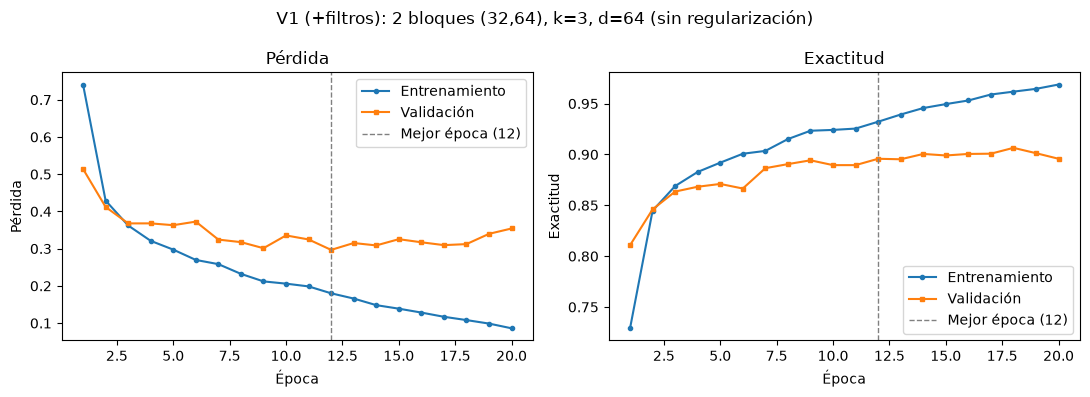

Sin regularización (época 20) -> train_acc: 0.9688 | val_acc: 0.8958 | brecha: 0.0730 | val_loss final: 0.3542 (mín: 0.2967)


In [19]:
nombre_mejor_v = "V1 (+filtros): 2 bloques (32,64), k=3, d=64"
cfg_mejor, hist_mejor_sin_reg = historiales_variantes[nombre_mejor_v]
graficar_curvas(hist_mejor_sin_reg, titulo=f"{nombre_mejor_v} (sin regularización)", marcar_mejor=True)
print(f"Sin regularización (época 20) -> train_acc: {hist_mejor_sin_reg['train_acc'][-1]:.4f} | "
      f"val_acc: {hist_mejor_sin_reg['val_acc'][-1]:.4f} | "
      f"brecha: {hist_mejor_sin_reg['train_acc'][-1] - hist_mejor_sin_reg['val_acc'][-1]:.4f} | "
      f"val_loss final: {hist_mejor_sin_reg['val_loss'][-1]:.4f} (mín: {min(hist_mejor_sin_reg['val_loss']):.4f})")

**Diagnóstico de sobreajuste y cómo lo corregimos:**
- En las curvas sin regularización, la pérdida de entrenamiento baja casi a cero (`~0.07`) y la exactitud de entrenamiento supera el `97 %`, mientras que la pérdida de validación deja de bajar alrededor de la época 10 (`~0.29`) y empieza a subir hasta `~0.37`, abriendo una brecha de más de **7 puntos porcentuales** entre entrenamiento y validación.
- Para corregirlo combinamos:
  1. **Dropout (`dropout = 0.30`):** durante `model.train()`, apaga aleatoriamente el 30 % de las neuronas de la capa densa en cada paso (y escala las activaciones restantes por $1/(1-p)$), evitando que las neuronas co-adapten sus pesos. Durante `model.eval()`, el dropout se desactiva y se utilizan todas las neuronas de forma determinista.
  2. **Weight decay (`weight_decay = 1e-4`):** penalización $L_2$ en el optimizador que mantiene los pesos pequeños y suaviza la frontera de decisión.
  3. **Early stopping (`paciencia = 5`):** monitorea la pérdida de validación al final de cada época, detiene el entrenamiento cuando no mejora durante 5 épocas seguidas y restaura automáticamente los pesos (`state_dict`) de la mejor época.

In [20]:
fijar_semilla(SEMILLA)
train_loader_reg, val_loader_reg, _ = crear_dataloaders(train_ds, val_ds, test_ds, batch_size=BATCH_SIZE)
mejor_cnn = CNN(canales=(32, 64), kernel_size=3, ocultas=(64,), dropout=0.30)
hist_mejor_cnn = entrenar(
    mejor_cnn, train_loader_reg, val_loader_reg,
    epocas=EPOCAS, lr=LR, weight_decay=1e-4, paciencia=5,
    dispositivo=dispositivo, verbose=True
)

ep_opt = hist_mejor_cnn["mejor_epoca"] - 1
print(f"\nModelo restaurado en su mejor época ({hist_mejor_cnn['mejor_epoca']}):")
print(f"  train_acc: {hist_mejor_cnn['train_acc'][ep_opt]:.4f} | val_acc: {hist_mejor_cnn['val_acc'][ep_opt]:.4f} "
      f"| brecha: {hist_mejor_cnn['train_acc'][ep_opt] - hist_mejor_cnn['val_acc'][ep_opt]:.4f} "
      f"| val_loss: {hist_mejor_cnn['val_loss'][ep_opt]:.4f}")

torch.save(mejor_cnn.state_dict(), "mejor_cnn.pt")
print("Pesos de la mejor CNN guardados en mejor_cnn.pt")

Época  1/20 | pérdida train 0.8536 val 0.5224 | exactitud train 0.6914 val 0.7960


Época  2/20 | pérdida train 0.5073 val 0.4280 | exactitud train 0.8129 val 0.8415


Época  3/20 | pérdida train 0.4337 val 0.3764 | exactitud train 0.8410 val 0.8602


Época  4/20 | pérdida train 0.3882 val 0.3722 | exactitud train 0.8589 val 0.8622


Época  5/20 | pérdida train 0.3553 val 0.3434 | exactitud train 0.8706 val 0.8728


Época  6/20 | pérdida train 0.3291 val 0.3271 | exactitud train 0.8806 val 0.8800


... (10 outputs left out)

Época 17/20 | pérdida train 0.1829 val 0.2875 | exactitud train 0.9299 val 0.9028


Época 18/20 | pérdida train 0.1788 val 0.2982 | exactitud train 0.9330 val 0.9050


Época 19/20 | pérdida train 0.1665 val 0.3224 | exactitud train 0.9381 val 0.9050


Época 20/20 | pérdida train 0.1650 val 0.3170 | exactitud train 0.9381 val 0.8988
Early stopping en época 20 (mejor val_loss en época 15: 0.2873)

Modelo restaurado en su mejor época (15):
  train_acc: 0.9247 | val_acc: 0.9028 | brecha: 0.0220 | val_loss: 0.2873
Pesos de la mejor CNN guardados en mejor_cnn.pt


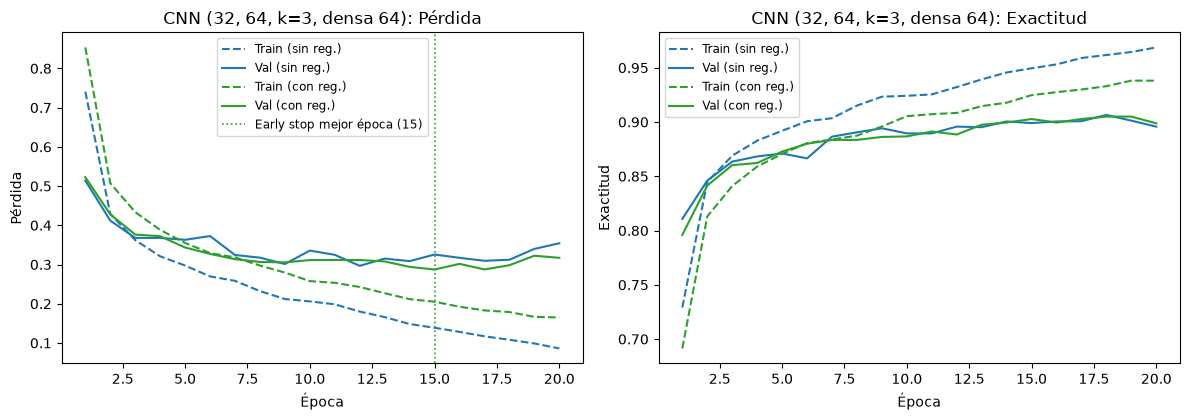

In [21]:
comparar_curvas_regularizacion(hist_mejor_sin_reg, hist_mejor_cnn, nombre_arq="CNN (32, 64, k=3, densa 64)")

### 3.5 Exactitud de prueba del MLP y de la mejor CNN (evaluada una sola vez)

In [22]:
criterio_eval = nn.CrossEntropyLoss()

# Cargamos los pesos guardados para verificar que la evaluación puede reproducirse sin reentrenar
mlp.load_state_dict(torch.load("mlp.pt", map_location=dispositivo))
mejor_cnn.load_state_dict(torch.load("mejor_cnn.pt", map_location=dispositivo))

test_loss_mlp, test_acc_mlp = evaluar(mlp, test_loader, criterio_eval, dispositivo)
test_loss_cnn, test_acc_cnn = evaluar(mejor_cnn, test_loader, criterio_eval, dispositivo)

print(f"Exactitud en PRUEBA (10 000 imágenes):")
print(f"  MLP       ({contar_parametros(mlp):>7,} parámetros) -> pérdida test: {test_loss_mlp:.4f} | exactitud test: {test_acc_mlp:.4f} ({100*test_acc_mlp:.2f}%)")
print(f"  Mejor CNN ({contar_parametros(mejor_cnn):>7,} parámetros) -> pérdida test: {test_loss_cnn:.4f} | exactitud test: {test_acc_cnn:.4f} ({100*test_acc_cnn:.2f}%)")

Exactitud en PRUEBA (10 000 imágenes):
  MLP       (235,146 parámetros) -> pérdida test: 0.5197 | exactitud test: 0.8654 (86.54%)
  Mejor CNN (220,234 parámetros) -> pérdida test: 0.2907 | exactitud test: 0.8999 (89.99%)


---
## Punto 4. Análisis

### 4.1 Matriz de confusión e imágenes mal clasificadas de la mejor CNN en prueba

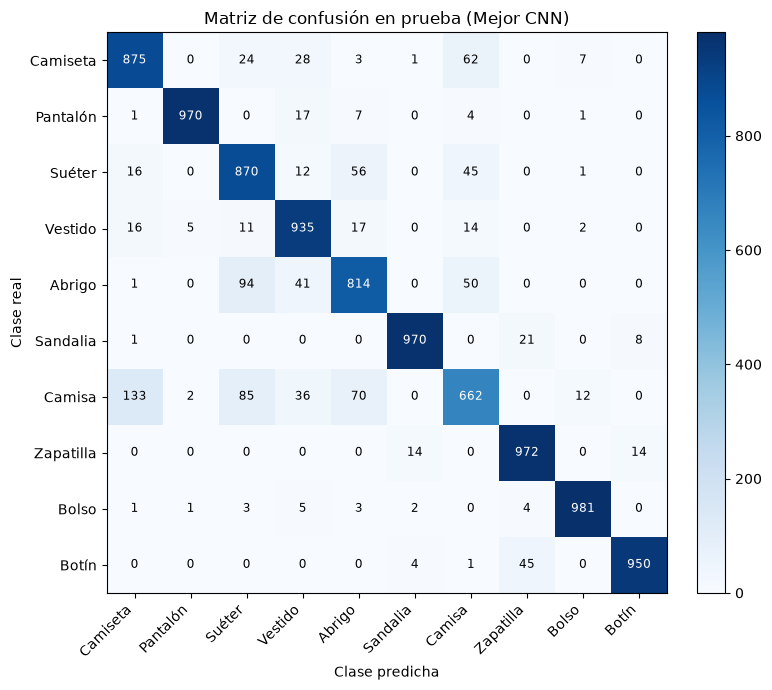

Principales pares confundidos (Real -> Predicha: casos):
  Camisa     -> Camiseta  : 133 ejemplos
  Abrigo     -> Suéter    :  94 ejemplos
  Camisa     -> Suéter    :  85 ejemplos
  Camisa     -> Abrigo    :  70 ejemplos
  Camiseta   -> Camisa    :  62 ejemplos
  Suéter     -> Abrigo    :  56 ejemplos
  Abrigo     -> Camisa    :  50 ejemplos
  Suéter     -> Camisa    :  45 ejemplos


In [23]:
imgs_test, y_real_test, y_pred_test, probs_test = predecir_conjunto(mejor_cnn, test_loader, dispositivo)
matriz_conf = graficar_matriz_confusion(y_real_test, y_pred_test, nombres=NOMBRES_CLASES)

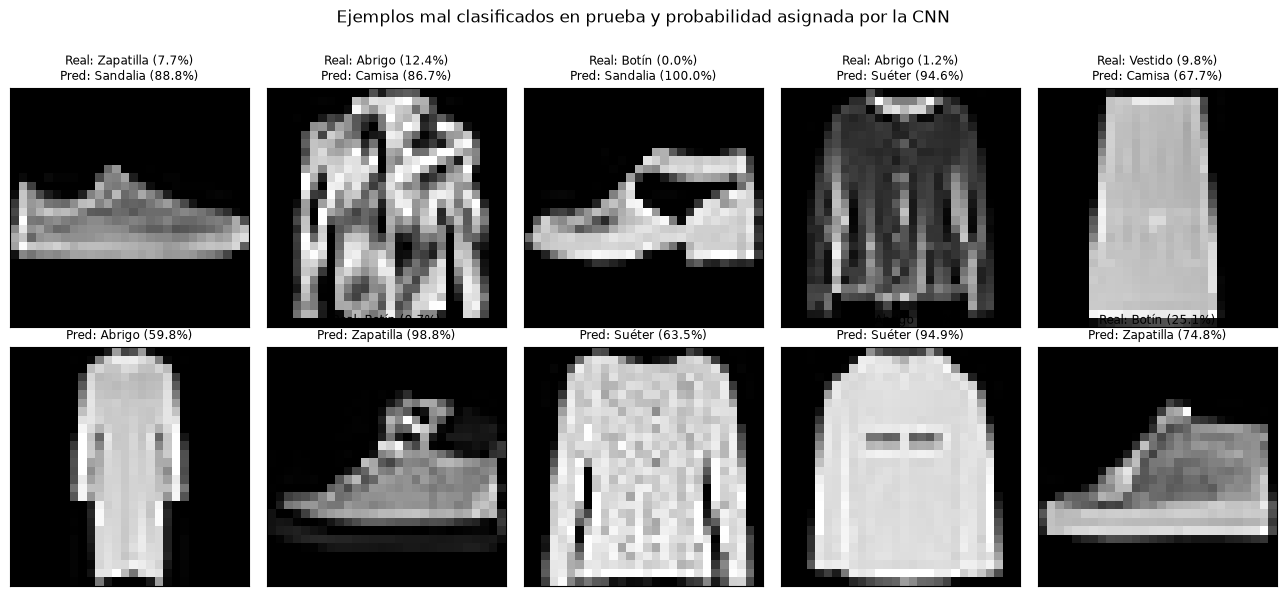

In [24]:
mostrar_mal_clasificadas(imgs_test, y_real_test, y_pred_test, probs_test, nombres=NOMBRES_CLASES, n_mostrar=10)

**Interpretación de la matriz de confusión y los errores:**
- Las clases con silueta muy distintiva (**Pantalón**, **Bolso**, **Sandalia**, **Zapatilla** y **Botín**) tienen una exactitud muy alta (más de `95 %` de aciertos en la diagonal principal).
- La mayor fuente de confusión ocurre dentro del grupo de prendas superiores de torso (**Camisa**, **Camiseta**, **Suéter** y **Abrigo**), especialmente entre **Camisa ↔ Camiseta**, **Camisa ↔ Suéter** y **Camisa ↔ Abrigo**. En imágenes en escala de grises de $28\times 28$ píxeles, los botones o cuellos de una camisa apenas ocupan 1–2 píxeles y su silueta exterior es casi idéntica a la de una camiseta o un suéter/abrigo.
- Un segundo grupo menor de confusión se da entre calzado (**Botín ↔ Zapatilla ↔ Sandalia**), cuando la altura de la caña o las aberturas no son nítidas a baja resolución.

### 4.2 Visualización de los filtros de la primera capa convolucional

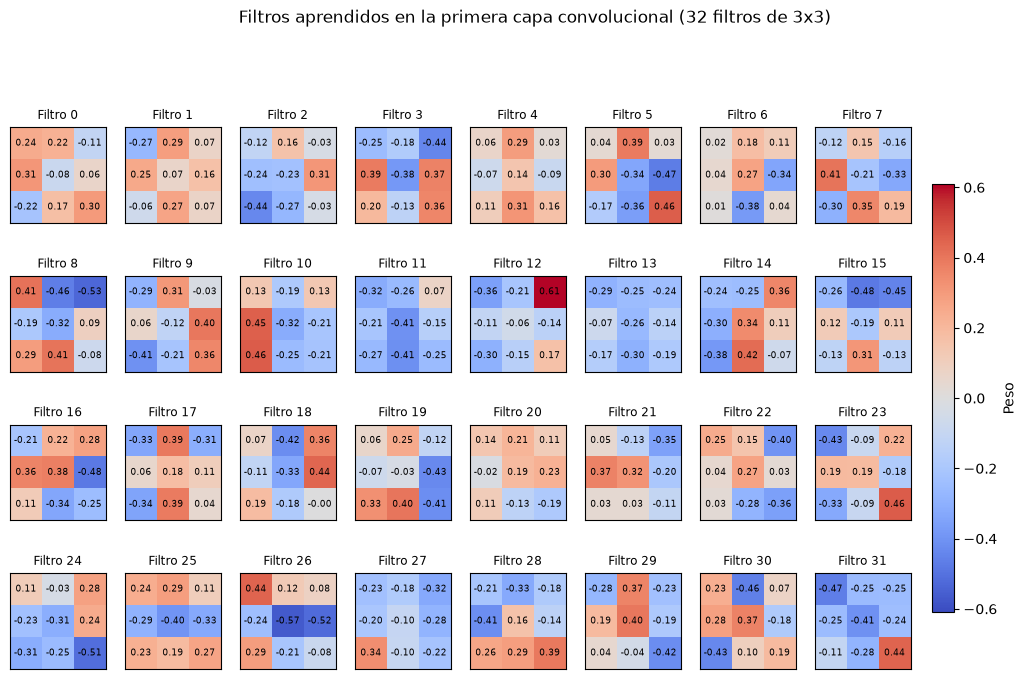

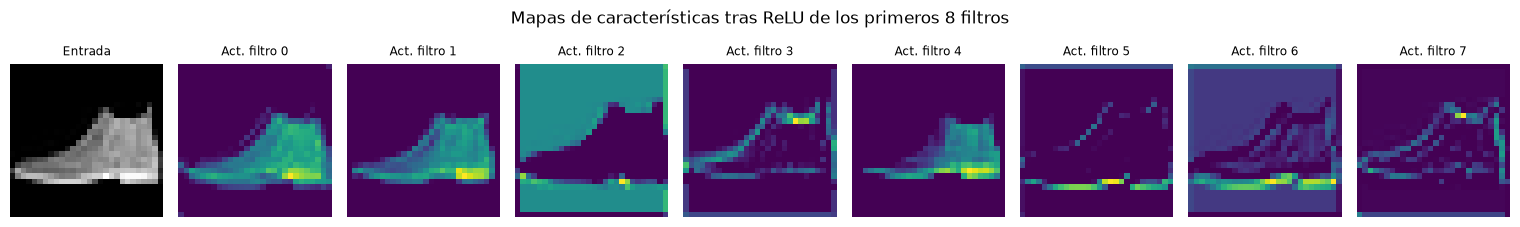

In [25]:
visualizar_filtros_conv1(mejor_cnn, img_ejemplo=imgs_test[0])

**¿Qué patrones detectan los filtros de la primera capa convolucional?**
- Cada filtro de la primera capa es una matriz de $3\times 3$ pesos que opera directamente sobre las intensidades de la imagen en escala de grises:
  - **Detectores de bordes verticales:** filtros con pesos positivos (rojo) en la columna izquierda/derecha y negativos (azul) en el lado opuesto (similares al filtro $K$ del Punto 1), que se activan fuertemente en los contornos laterales de pantalones, vestidos, mangas y calzado.
  - **Detectores de bordes horizontales:** filtros con pesos positivos en la fila superior y negativos en la fila inferior (o viceversa), que resaltan cuellos, hombros, cinturas y suelas.
  - **Detectores de bordes diagonales y esquinas:** filtros con gradiente entre esquinas opuestas, sensibles a escotes, mangas inclinadas o la silueta diagonal del calzado.
  - **Detectores de contraste local / intensidad (centro vs. periferia):** filtros con centro positivo rodeado de negativos (o al revés), que responden a texturas puntuales, asas de bolsos o regiones brillantes sobre fondo oscuro.

### 4.3 Comparación entre MLP y CNN: número de parámetros y exactitud

In [26]:
ep_mlp_best = hist_mlp["mejor_epoca"] - 1
ep_cnn_best = hist_mejor_cnn["mejor_epoca"] - 1

print(f"{'Modelo':<34} | {'Parámetros':>10} | {'Train Acc':>10} | {'Val Acc':>10} | {'Test Acc':>10}")
print("-" * 86)
print(f"{'MLP (784 -> 256 -> 128 -> 10)':<34} | {contar_parametros(mlp):>10,} | "
      f"{hist_mlp['train_acc'][-1]:>10.4f} | {hist_mlp['val_acc'][-1]:>10.4f} | {test_acc_mlp:>10.4f}")
print(f"{'Mejor CNN (32-64, k=3, densa 64)':<34} | {contar_parametros(mejor_cnn):>10,} | "
      f"{hist_mejor_cnn['train_acc'][ep_cnn_best]:>10.4f} | {hist_mejor_cnn['val_acc'][ep_cnn_best]:>10.4f} | {test_acc_cnn:>10.4f}")
print(f"\nDiferencia a favor de la CNN en prueba: +{(test_acc_cnn - test_acc_mlp)*100:.2f} puntos porcentuales "
      f"con {contar_parametros(mlp) - contar_parametros(mejor_cnn):,} parámetros menos.")

Modelo                             | Parámetros |  Train Acc |    Val Acc |   Test Acc
--------------------------------------------------------------------------------------
MLP (784 -> 256 -> 128 -> 10)      |    235,146 |     0.9584 |     0.8705 |     0.8654
Mejor CNN (32-64, k=3, densa 64)   |    220,234 |     0.9247 |     0.9028 |     0.8999

Diferencia a favor de la CNN en prueba: +3.45 puntos porcentuales con 14,912 parámetros menos.


**¿Por qué la CNN funciona mejor con imágenes que el MLP teniendo incluso menos parámetros?**

1. **Preservación de la topología espacial 2D (conexiones locales):** el MLP aplana la imagen de $28\times 28$ en un vector 1D de $784$ entradas desde la primera capa, perdiendo la noción de qué píxeles son vecinos verticales o diagonales. La CNN opera con ventanas locales ($3\times 3$) que explotan la alta correlación entre píxeles adyacentes.
2. **Pesos compartidos e invarianza/equivarianza a la traslación:** en una capa convolucional, el mismo filtro de $3\times 3$ ($9$ pesos $+ 1$ sesgo) se desplaza por toda la imagen. Si un patrón (un borde de cuello o una suela) aparece desplazado unos píxeles, el mismo filtro lo detecta sin necesidad de aprender pesos distintos para cada posición como ocurre en una capa densa.
3. **Jerarquía de características y reducción espacial con pooling:** el primer bloque detecta bordes y contrastes simples; el segundo bloque combina esos bordes en partes de prendas (mangas, cuellos, tacones), y las capas `MaxPool2d(2, 2)` resumen regiones locales otorgando robustez a pequeñas traslaciones o deformaciones y reduciendo el tamaño antes de llegar a las capas densas. Gracias a este sesgo inductivo espacial, la CNN generaliza mucho mejor en el conjunto de prueba.